In [8]:
report_figs = ["01_demand_histogram.png", "03_inventory_vs_expected_profit.png",
               "05_policy_profit_distribution.png", "06_policy_comparison_by_variability.png",
               "08_effect_of_demand_variability.png", "09_effect_of_cost_parameters.png",
               "07_effect_of_mean_demand.png", "02_convergence_Q120.png"]
for f in report_figs:
    shutil.copy2(os.path.join(GRAPHS_DIR, f), os.path.join(REPORT_FIG_DIR, f))
print("Copied", len(report_figs), "figures to", os.path.abspath(REPORT_FIG_DIR))
print(sorted(os.listdir(REPORT_FIG_DIR)))

Copied 8 figures to c:\Users\vishw\Desktop\E-com\report\figures
['01_demand_histogram.png', '02_convergence_Q120.png', '03_inventory_vs_expected_profit.png', '05_policy_profit_distribution.png', '06_policy_comparison_by_variability.png', '07_effect_of_mean_demand.png', '08_effect_of_demand_variability.png', '09_effect_of_cost_parameters.png']


## Module 12 summary
- All five required visualizations exist and were saved from computed results: demand histogram, Q vs expected profit, stochastic vs deterministic comparison, effect of demand variability, and effect of cost parameters. Eight figures were copied to report/figures.
- Four result tables were built directly from the saved CSV files (no retyped numbers) and saved in results/tables.
- Consistency checks passed: the base-case profit (₹76,151) is identical across Experiments A, B, C and Table 1, and the deterministic prediction (₹84,000) exceeds the simulated profit in every variability case.
- Base case: both policies order 120 units. Test profit is ₹76,151, stockout frequency is 0.475, and the deterministic model overstates profit by about ₹7,849.
- Variability: Q* ranges only from 117 to 120, but average profit falls from ₹76,151 to ₹61,466 and 5th percentile profit from ₹55,200 to ₹11,500.
- Costs: Q* differs from 120 in 11 of 15 rows. The largest gain from stochastic optimization is 0.65% of profit, and only h = 0 is not distinguishable from zero.
- Conclusion: the main value of the stochastic model here is realistic profit and risk estimates, not a very different order quantity.
- All parameter values are illustrative assumptions and demand is synthetic.

In [7]:
print(f"Base case Q* = Q_det = {int(t1['Q'].iloc[0])}; test avg profit = ₹{base_profit:,.0f}")
print(f"Deterministic predicted profit = ₹{t1.loc['Deterministic','model_predicted_profit']:,.0f}")
print(f"Stockout frequency (base) = {t1.loc['Stochastic','stockout_freq']:.3f}")

print(f"\nVariability: profit falls from ₹{t2['test_profit_stoch'].iloc[0]:,.0f} "
      f"to ₹{t2['test_profit_stoch'].iloc[-1]:,.0f}; "
      f"5th percentile from ₹{t2['p5_profit_stoch'].iloc[0]:,.0f} to ₹{t2['p5_profit_stoch'].iloc[-1]:,.0f}")
print(f"Q* range over variability cases: {t2['Q_star'].min()} to {t2['Q_star'].max()}")

changed = t3[t3["Q_star"] != t3["Q_det"]]
print(f"\nCost rows where Q* differs from 120: {len(changed)} of {len(t3)}")
print(f"Largest gain: {t3['gain_pct_of_det_profit'].max():.2f}% of deterministic profit")
print("Rows not distinguishable from zero:",
      t3.loc[~t3["distinguishable_from_zero"] & (t3["Q_star"] != t3["Q_det"]), ["parameter", "value"]].values.tolist())

Base case Q* = Q_det = 120; test avg profit = ₹76,151
Deterministic predicted profit = ₹84,000
Stockout frequency (base) = 0.470

Variability: profit falls from ₹76,151 to ₹61,466; 5th percentile from ₹55,200 to ₹11,500
Q* range over variability cases: 117 to 120

Cost rows where Q* differs from 120: 11 of 15
Largest gain: 0.65% of deterministic profit
Rows not distinguishable from zero: [['h', 0]]


In [6]:
base_profit = t1.loc["Stochastic", "avg_profit"]

checks = []
checks.append(("Base case: Q_det == Q_stoch == 120",
               t1["Q"].tolist() == [120, 120]))
checks.append(("Experiment A (mean 120) matches Table 1 profit",
               np.isclose(t4.loc[t4["mean_demand"] == 120, "test_profit_stoch"].iloc[0], base_profit)))
checks.append(("Experiment B (Poisson) matches Table 1 profit",
               np.isclose(t2.iloc[0]["test_profit_stoch"], base_profit)))
for param, base_value in [("c", 800), ("h", 100), ("s", 200)]:
    row = t3[(t3["parameter"] == param) & (t3["value"] == base_value)].iloc[0]
    checks.append((f"Experiment C base row ({param} = {base_value}) matches Table 1 profit",
                   np.isclose(row["test_profit_stoch"], base_profit)))
checks.append(("Deterministic prediction (84,000) exceeds simulated profit in every Table 2 row",
               bool((t2["det_prediction_error"] > 0).all())))
checks.append(("Q* within 2 units of theory in every cost row",
               bool((t3["Q_star"] - t3["Q_theory"]).abs().le(2).all())))

for description, passed in checks:
    print(("PASS  " if passed else "FAIL  ") + description)
assert all(p for _, p in checks), "Inconsistency found - investigate before writing the report."

PASS  Base case: Q_det == Q_stoch == 120
PASS  Experiment A (mean 120) matches Table 1 profit
PASS  Experiment B (Poisson) matches Table 1 profit
PASS  Experiment C base row (c = 800) matches Table 1 profit
PASS  Experiment C base row (h = 100) matches Table 1 profit
PASS  Experiment C base row (s = 200) matches Table 1 profit
PASS  Deterministic prediction (84,000) exceeds simulated profit in every Table 2 row
PASS  Q* within 2 units of theory in every cost row


In [5]:
print("Table 3: cost parameters")
display(t3.round(3))
print("Table 4: mean demand")
display(t4.round(2))

Table 3: cost parameters


,parameter,value,critical_ratio,Q_star,Q_theory,Q_det,test_profit_stoch,test_profit_det,diff_stoch_minus_det,diff_ci95_half_width,gain_pct_of_det_profit,distinguishable_from_zero
0,c,600,0.611,123,123,120,100425.08,100151.06,274.02,50.855,0.274,True
1,c,700,0.556,121,121,120,88205.52,88151.06,54.46,17.618,0.062,True
2,c,800,0.500,120,120,120,76151.06,76151.06,0.00,0.000,0.000,False
3,c,900,0.444,118,118,120,64242.34,64151.06,91.28,34.590,0.142,True
4,c,1000,0.389,117,117,120,52490.24,52151.06,339.18,50.948,0.650,True
5,h,0,0.529,121,121,120,76593.41,76586.42,6.99,16.639,0.009,False
6,h,50,0.514,120,120,120,76368.74,76368.74,0.00,0.000,0.000,False
7,h,100,0.500,120,120,120,76151.06,76151.06,0.00,0.000,0.000,False
8,h,200,0.474,119,119,120,75741.76,75715.70,26.06,18.615,0.034,True
9,h,400,0.429,118,118,120,75018.14,74844.98,173.16,40.355,0.231,True


Table 4: mean demand


,mean_demand,Q_star,Q_theory,Q_det,test_profit_stoch,test_profit_det,diff_stoch_minus_det,stockout_freq_stoch
0,80,80,80,80,49596.22,49596.22,0.0,0.47
1,100,100,100,100,62827.36,62827.36,0.0,0.47
2,120,120,120,120,76151.06,76151.06,0.0,0.47
3,150,150,150,150,96218.82,96218.82,0.0,0.48
4,180,180,180,180,116375.48,116375.48,0.0,0.48


In [4]:
# Table 1: base case, both policies on the independent test scenarios
t1 = pd.read_csv(os.path.join(TABLES_DIR, "policy_comparison_base.csv"), index_col=0)
det_sum = pd.read_csv(os.path.join(TABLES_DIR, "deterministic_optimal_summary.csv"))
stoch_sum = pd.read_csv(os.path.join(TABLES_DIR, "stochastic_optimal_summary.csv"))
t1["model_predicted_profit"] = [det_sum["deterministic_predicted_profit"].iloc[0],
                                stoch_sum["expected_profit_at_Q"].iloc[0]]


def add_comparison_columns(df):
    """Add percentage gain and a flag for whether the gain exceeds its 95% interval."""
    df = df.copy()
    df["gain_pct_of_det_profit"] = 100 * df["diff_stoch_minus_det"] / df["test_profit_det"]
    df["distinguishable_from_zero"] = df["diff_stoch_minus_det"].abs() > df["diff_ci95_half_width"]
    return df


# Table 2: demand variability (mean fixed at 120)
t2 = pd.read_csv(os.path.join(OUT_DIR, "experiment_B_variability.csv"))
t2["det_prediction_error"] = t2["det_predicted_profit"] - t2["test_profit_stoch"]
t2["gain_pct"] = 100 * t2["diff_stoch_minus_det"] / t2["test_profit_stoch"]
t2 = t2[["case", "demand_variance", "Q_star", "Q_theory", "Q_det", "det_predicted_profit",
         "test_profit_stoch", "det_prediction_error", "diff_stoch_minus_det",
         "diff_ci95_half_width", "stockout_freq_stoch", "p5_profit_stoch"]]

# Table 3: cost parameters
t3 = add_comparison_columns(pd.read_csv(os.path.join(OUT_DIR, "experiment_C_costs.csv")))
t3 = t3[["parameter", "value", "critical_ratio", "Q_star", "Q_theory", "Q_det",
         "test_profit_stoch", "test_profit_det", "diff_stoch_minus_det",
         "diff_ci95_half_width", "gain_pct_of_det_profit", "distinguishable_from_zero"]]

# Table 4: mean demand
t4 = pd.read_csv(os.path.join(OUT_DIR, "experiment_A_mean_demand.csv"))
t4 = t4[["mean_demand", "Q_star", "Q_theory", "Q_det", "test_profit_stoch",
         "test_profit_det", "diff_stoch_minus_det", "stockout_freq_stoch"]]

t1.round(2).to_csv(os.path.join(TABLES_DIR, "table_1_base_case.csv"))
t2.round(2).to_csv(os.path.join(TABLES_DIR, "table_2_variability.csv"), index=False)
t3.round(3).to_csv(os.path.join(TABLES_DIR, "table_3_costs.csv"), index=False)
t4.round(2).to_csv(os.path.join(TABLES_DIR, "table_4_mean_demand.csv"), index=False)

print("Table 1: base case")
display(t1.round(2))
print("Table 2: demand variability")
display(t2.round(2))

Table 1: base case


,Q,avg_profit,se_profit,p5_profit,median_profit,p95_profit,avg_unsold,avg_unmet,stockout_freq,model_predicted_profit
policy,,,,,,,,,,
Deterministic,120.0,76151.06,94.94,55200.0,80800.0,83800.0,4.35,4.42,0.47,84000.0
Stochastic,120.0,76151.06,94.94,55200.0,80800.0,83800.0,4.35,4.42,0.47,76195.6


Table 2: demand variability


,case,demand_variance,Q_star,Q_theory,Q_det,det_predicted_profit,test_profit_stoch,det_prediction_error,diff_stoch_minus_det,diff_ci95_half_width,stockout_freq_stoch,p5_profit_stoch
0,Poisson (var 120),120,120,120,120,84000.0,76151.06,7848.94,0.00,0.00,0.47,55200.0
1,NegBin (var 240),240,120,119,120,84000.0,72737.72,11262.28,0.00,0.00,0.47,44000.0
2,NegBin (var 480),480,119,119,120,84000.0,68163.92,15836.08,26.82,17.63,0.49,30500.0
3,NegBin (var 960),960,117,118,120,84000.0,61466.32,22533.68,102.42,52.29,0.49,11500.0


01_demand_histogram.png


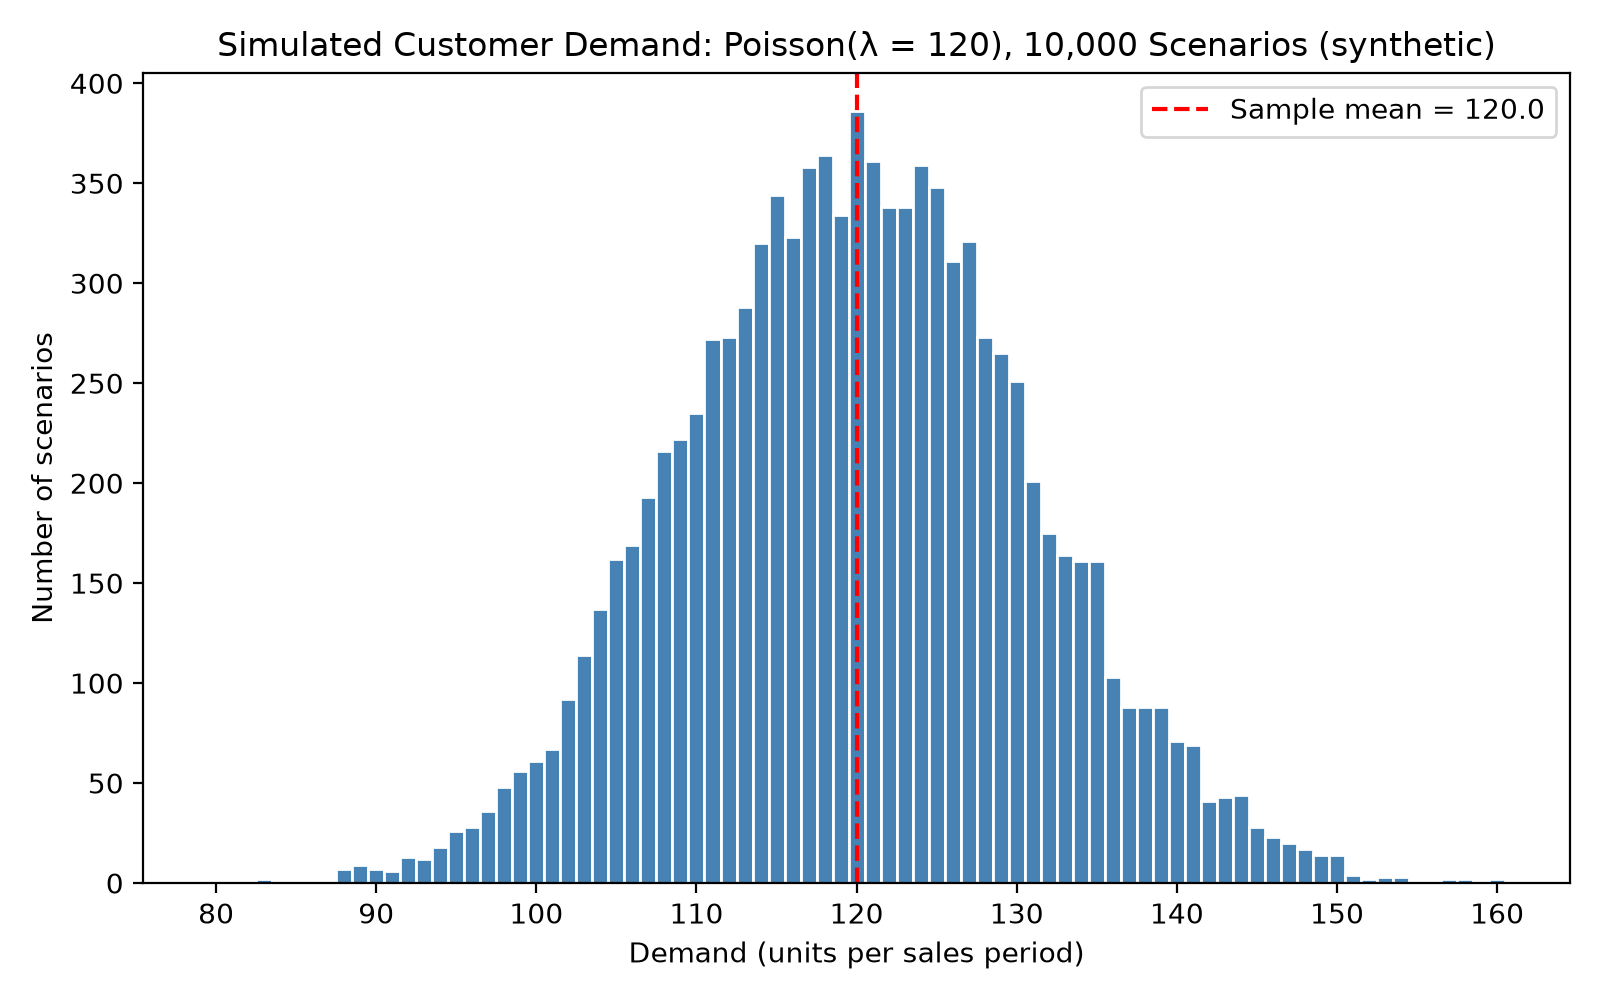

03_inventory_vs_expected_profit.png


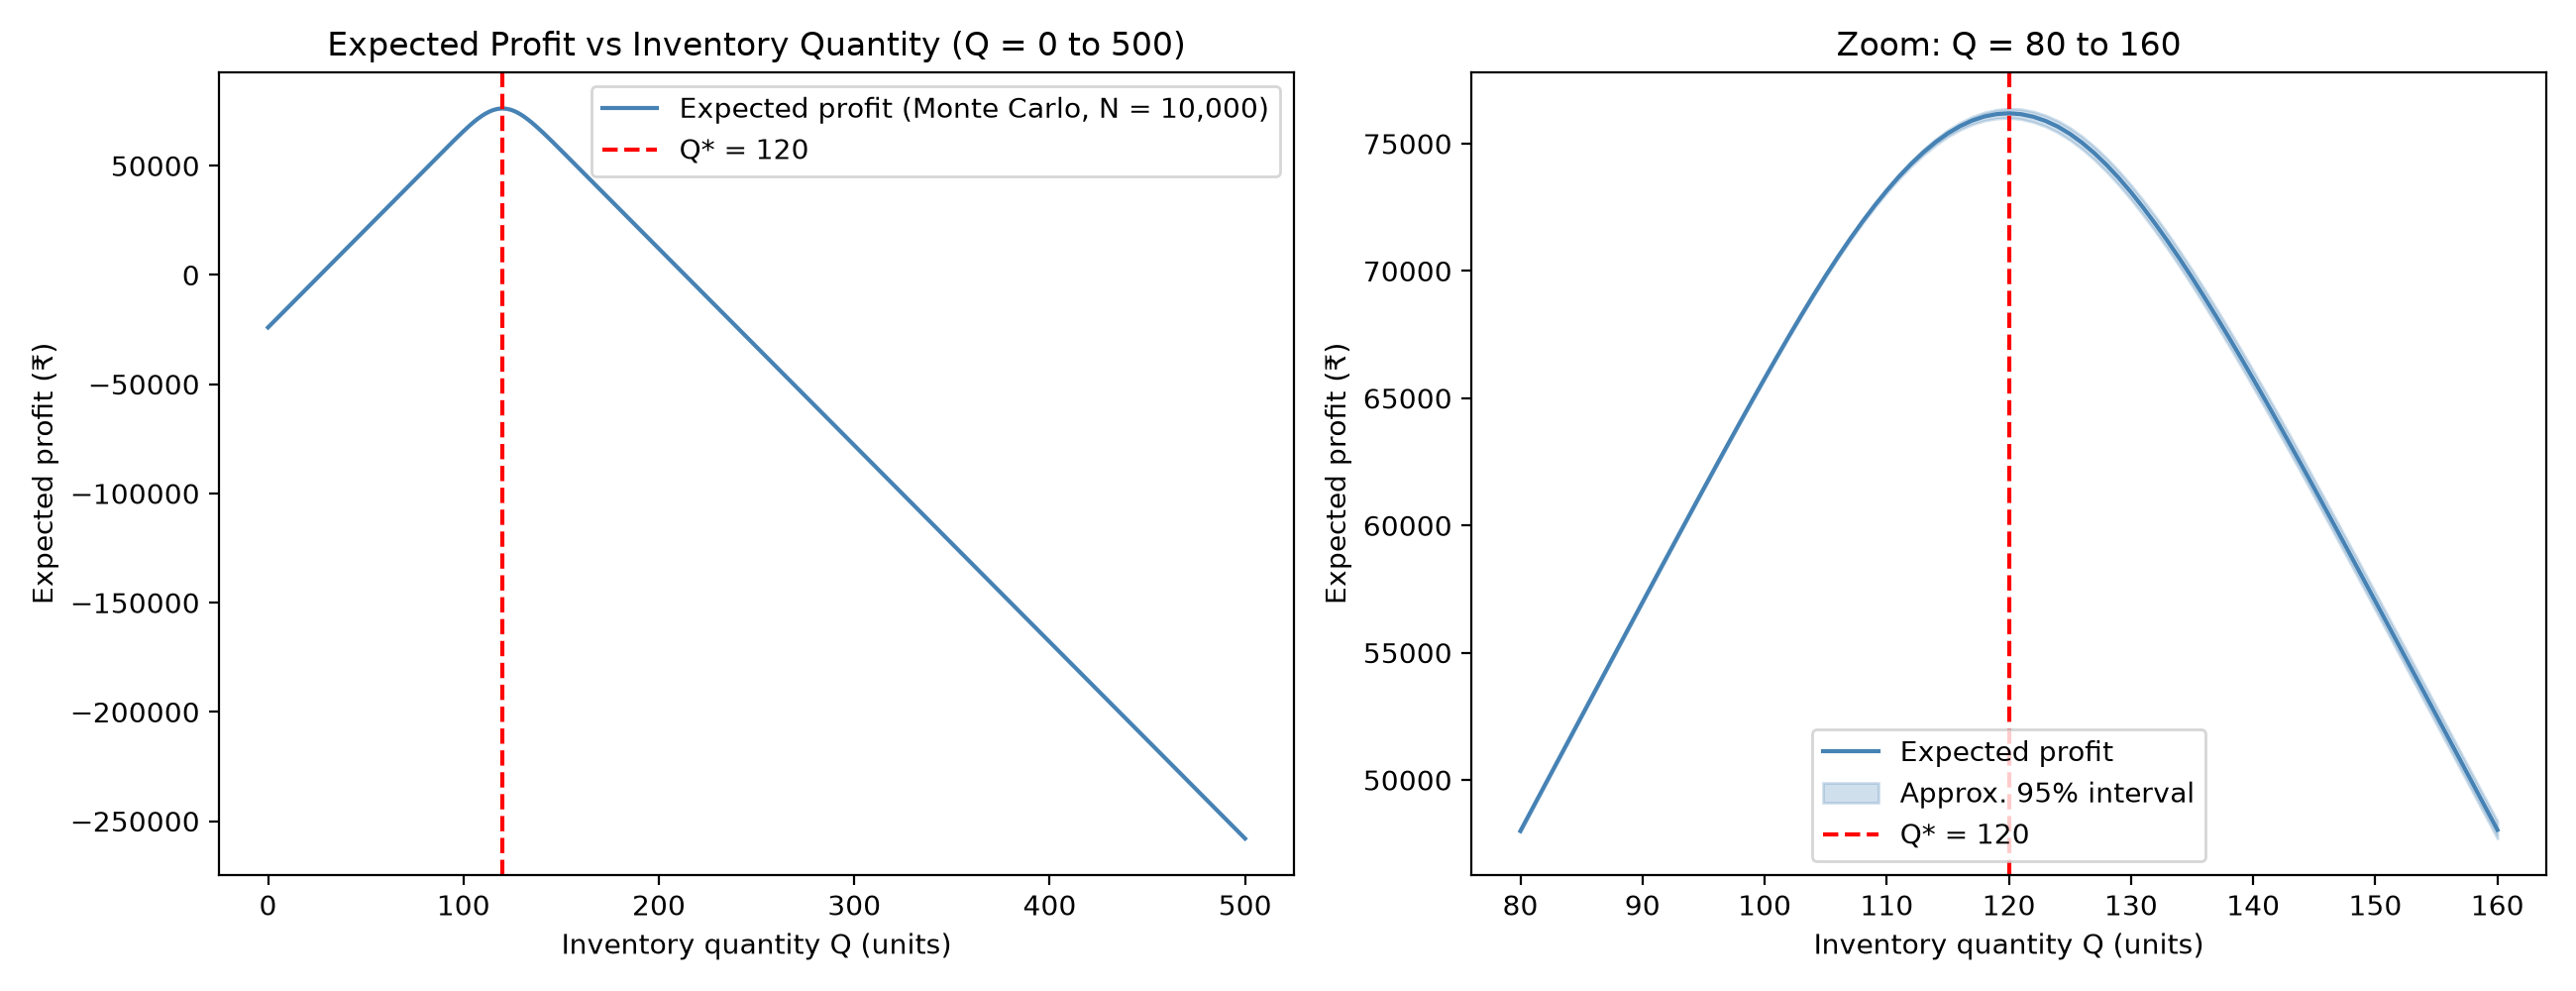

05_policy_profit_distribution.png


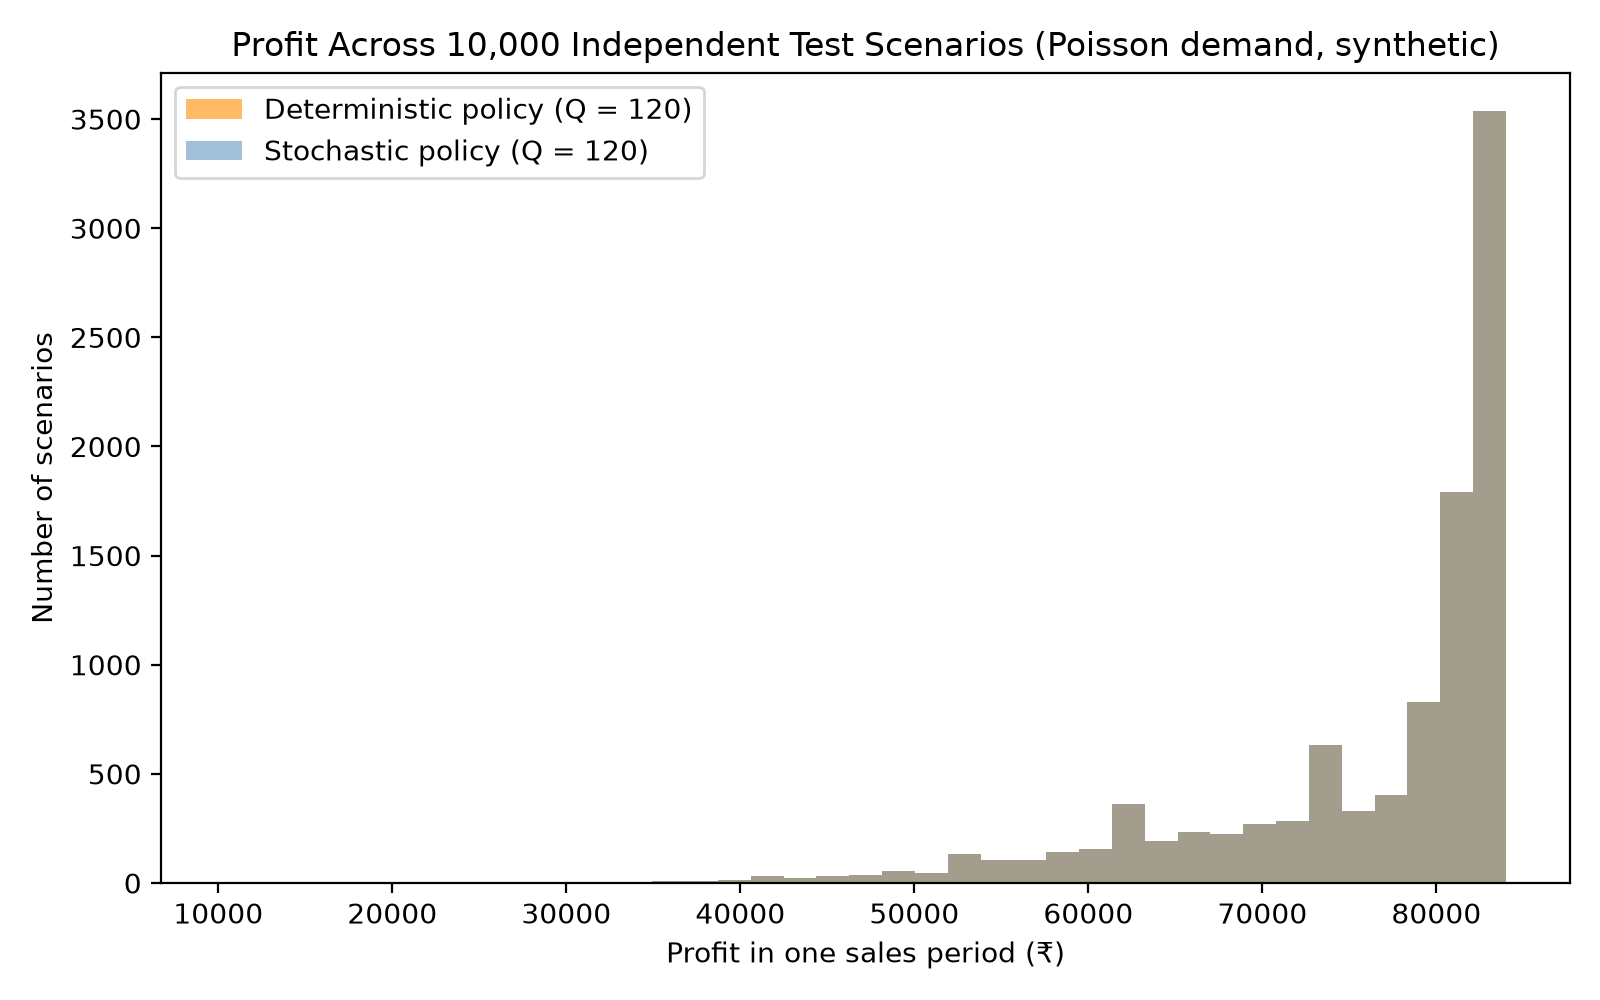

06_policy_comparison_by_variability.png


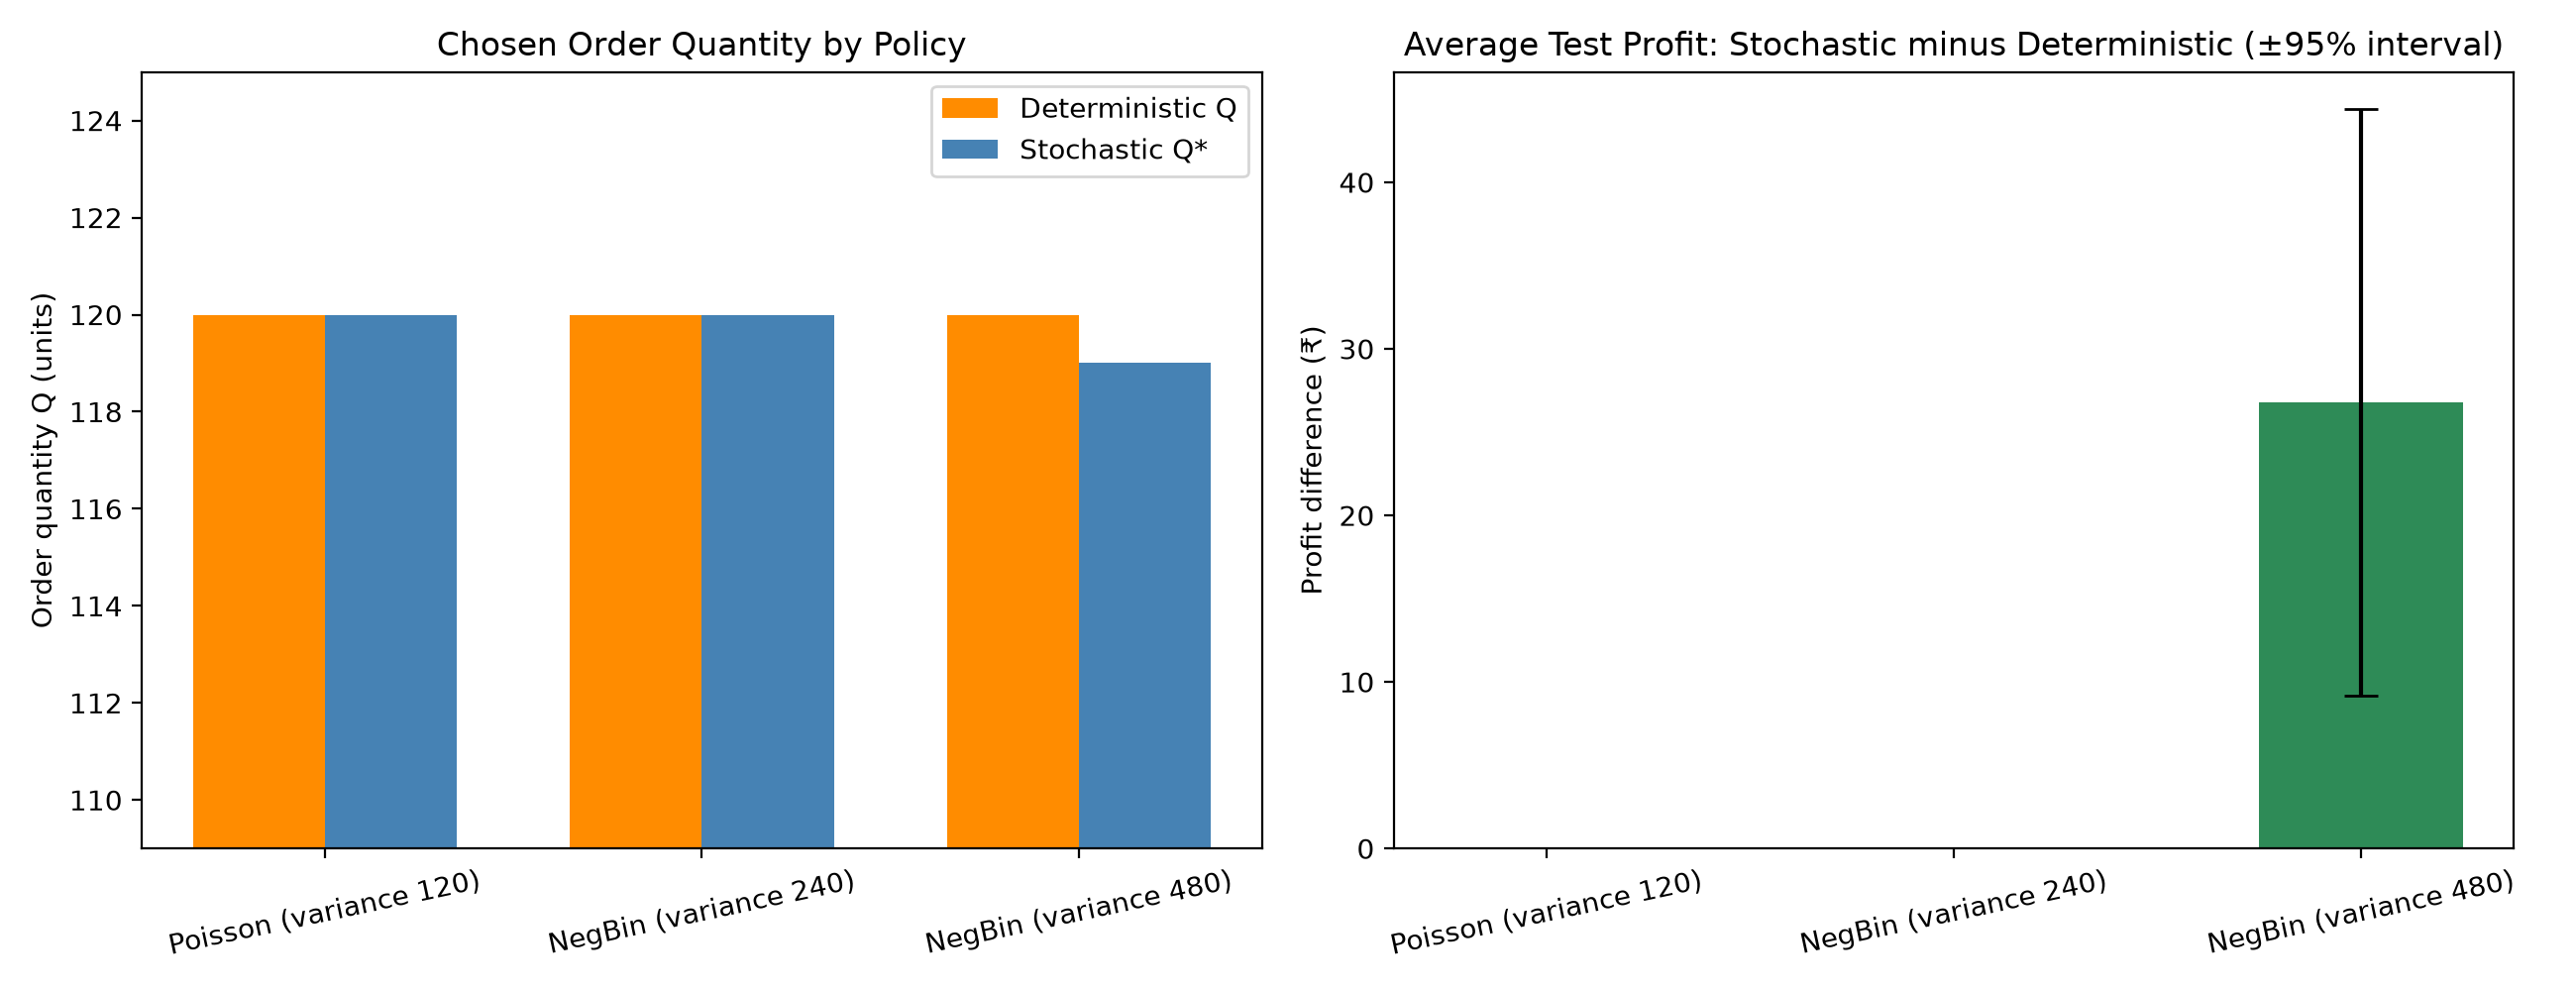

08_effect_of_demand_variability.png


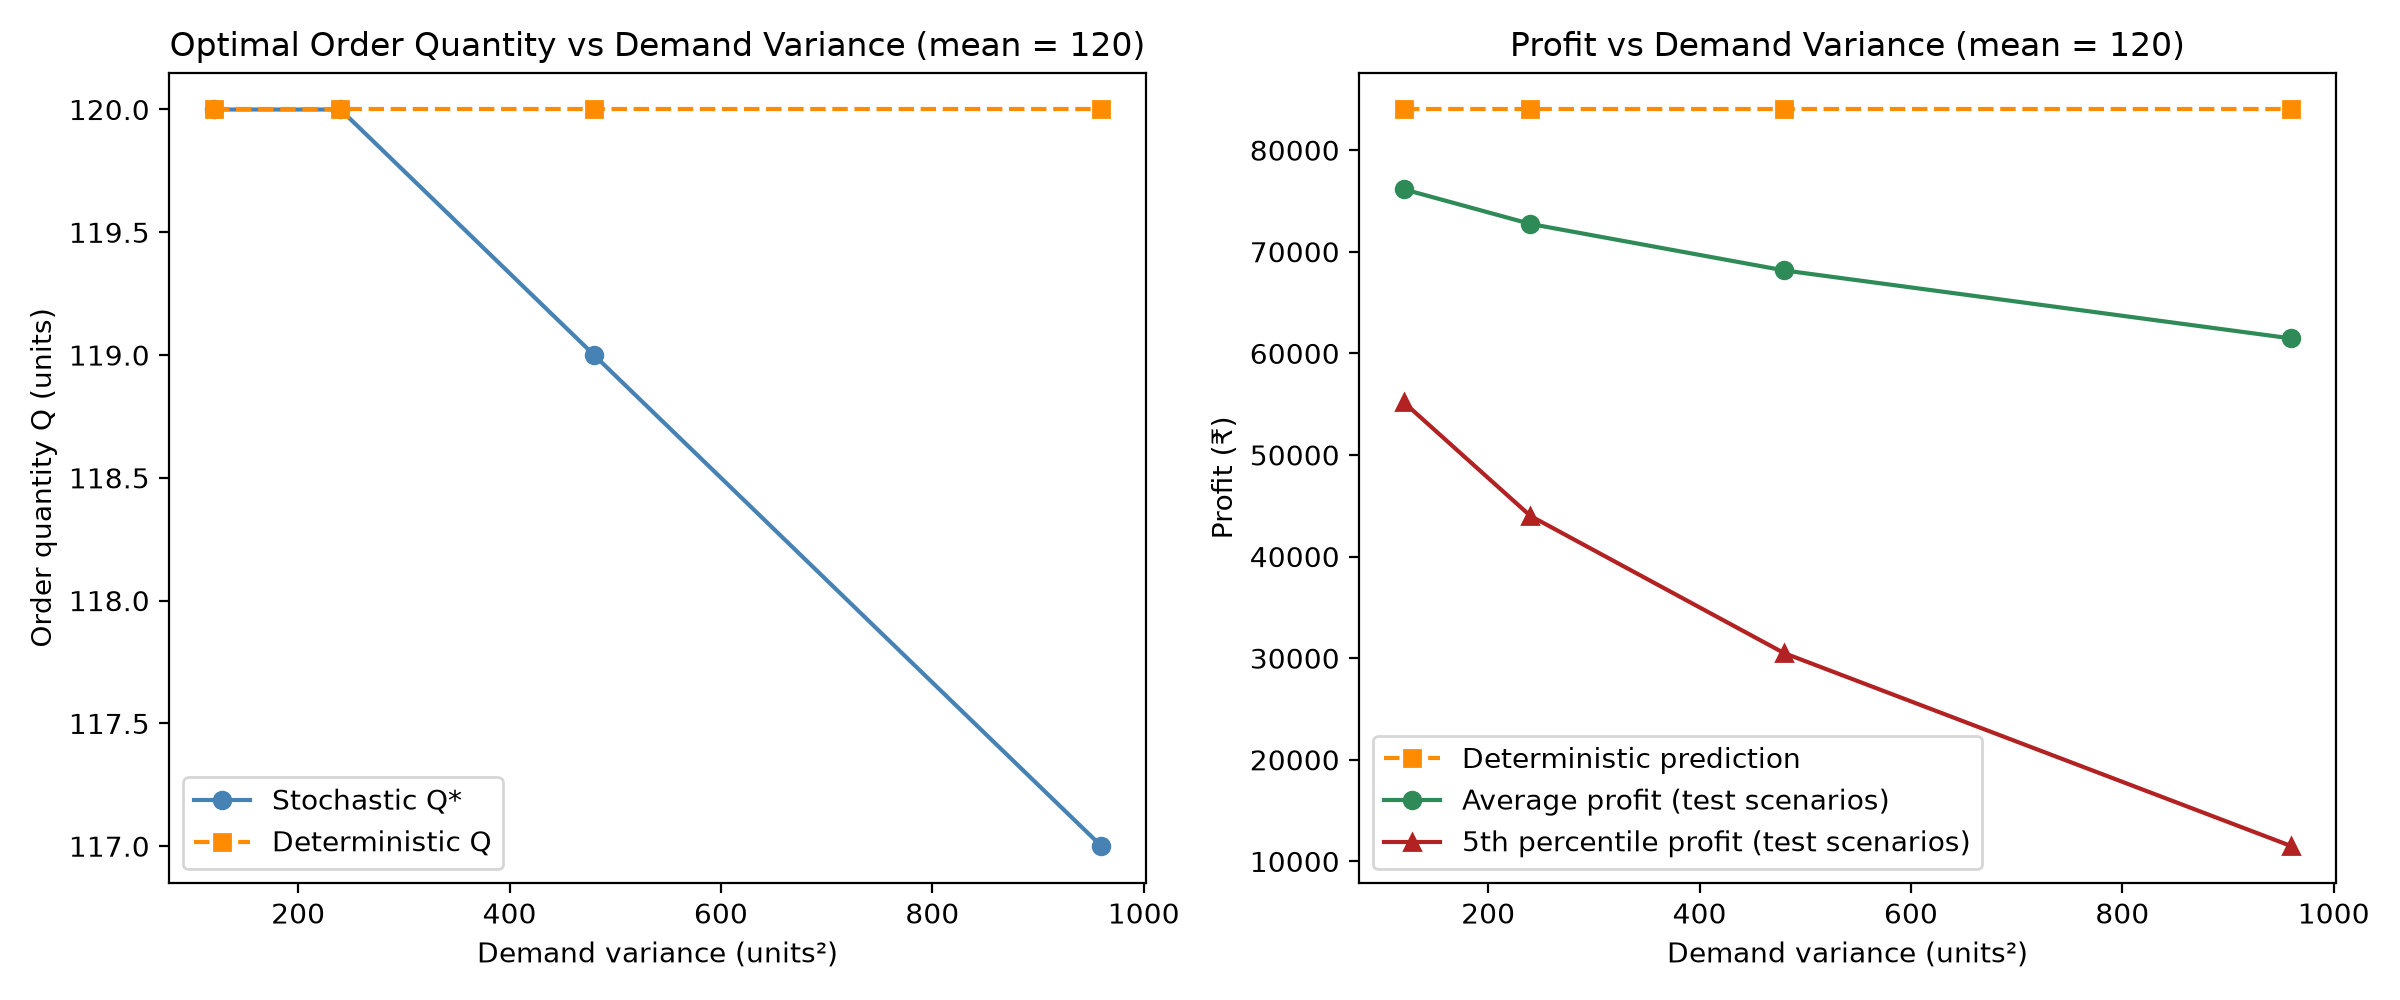

09_effect_of_cost_parameters.png


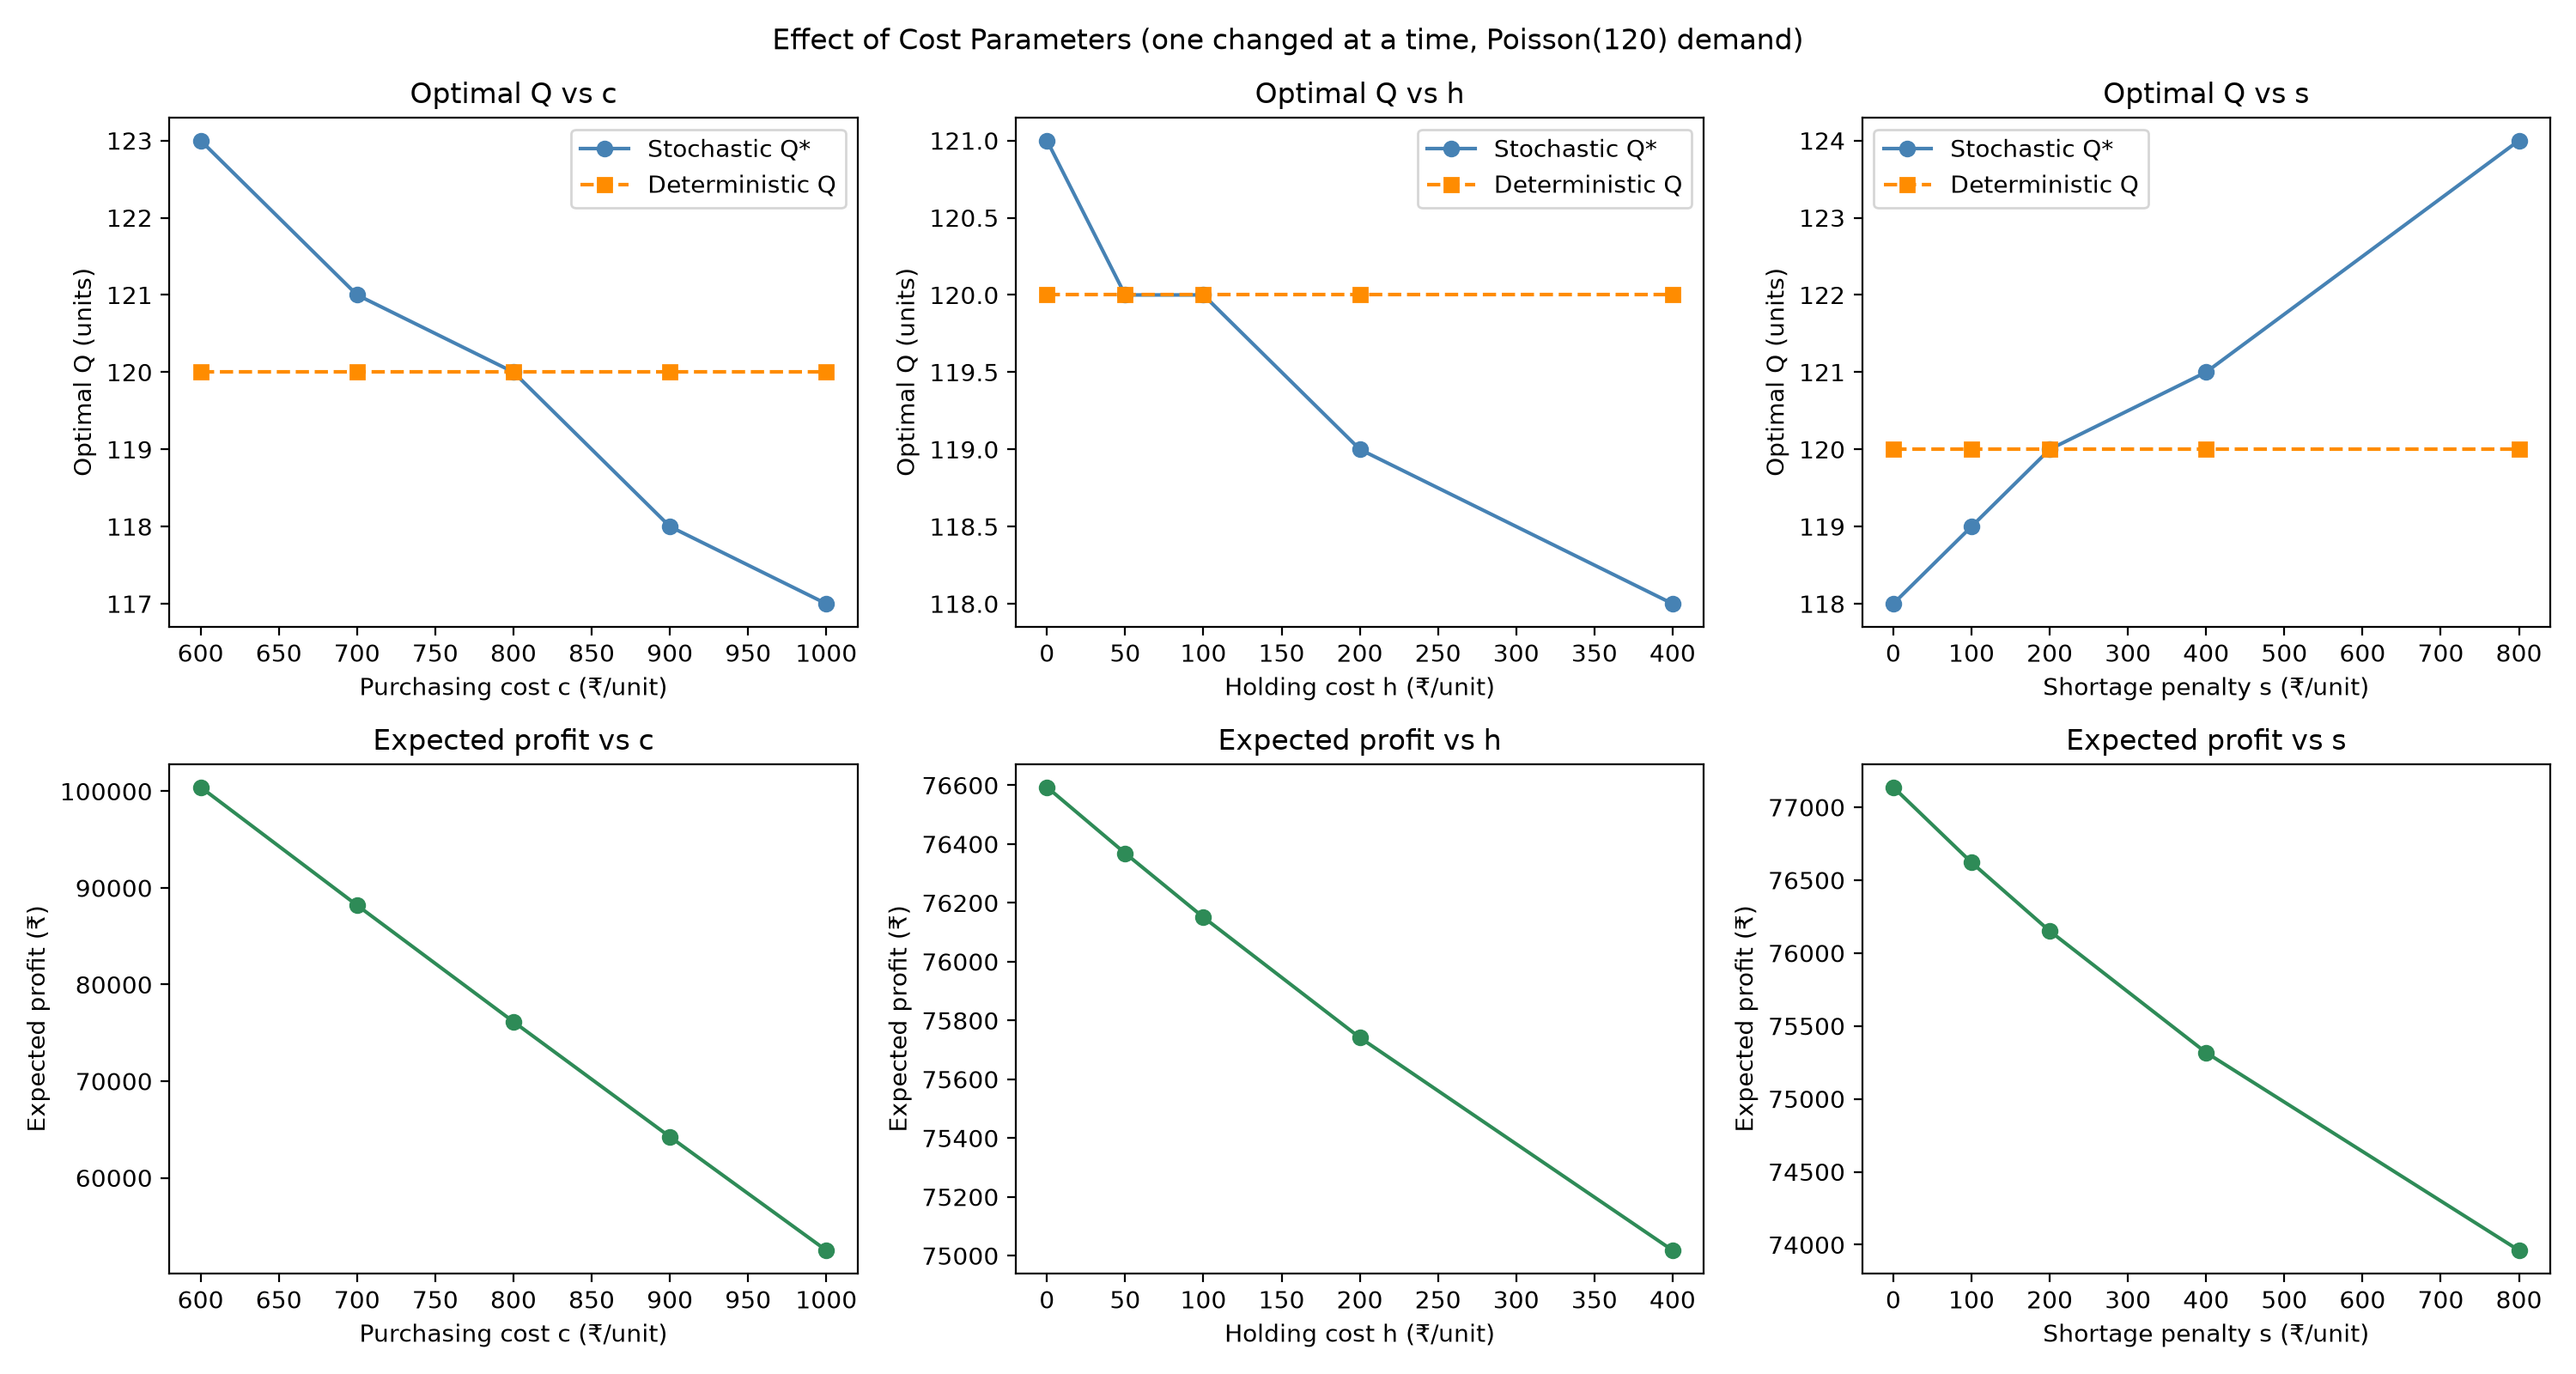

In [3]:
for f in ["01_demand_histogram.png", "03_inventory_vs_expected_profit.png",
          "05_policy_profit_distribution.png", "06_policy_comparison_by_variability.png",
          "08_effect_of_demand_variability.png", "09_effect_of_cost_parameters.png"]:
    print(f)
    display(Image(filename=os.path.join(GRAPHS_DIR, f), width=750))

In [2]:
required = {
    "1. Demand histogram": ["01_demand_histogram.png"],
    "2. Q vs expected profit": ["03_inventory_vs_expected_profit.png"],
    "3. Stochastic vs deterministic": ["05_policy_profit_distribution.png",
                                       "06_policy_comparison_by_variability.png"],
    "4. Effect of demand uncertainty": ["08_effect_of_demand_variability.png"],
    "5. Effect of cost parameters": ["09_effect_of_cost_parameters.png"],
}
supporting = ["02_convergence_Q120.png", "04_deterministic_profit_curve.png",
              "07_effect_of_mean_demand.png"]

all_ok = True
for name, files in required.items():
    for f in files:
        ok = os.path.isfile(os.path.join(GRAPHS_DIR, f))
        all_ok &= ok
        print(("OK       " if ok else "MISSING  ") + f"{name}: {f}")
for f in supporting:
    print(("OK       " if os.path.isfile(os.path.join(GRAPHS_DIR, f)) else "MISSING  ") + f"supporting: {f}")
print("\nAll required figures present:", all_ok)

OK       1. Demand histogram: 01_demand_histogram.png
OK       2. Q vs expected profit: 03_inventory_vs_expected_profit.png
OK       3. Stochastic vs deterministic: 05_policy_profit_distribution.png
OK       3. Stochastic vs deterministic: 06_policy_comparison_by_variability.png
OK       4. Effect of demand uncertainty: 08_effect_of_demand_variability.png
OK       5. Effect of cost parameters: 09_effect_of_cost_parameters.png
OK       supporting: 02_convergence_Q120.png
OK       supporting: 04_deterministic_profit_curve.png
OK       supporting: 07_effect_of_mean_demand.png

All required figures present: True


In [1]:
import os, shutil
import numpy as np
import pandas as pd
from IPython.display import Image, display

GRAPHS_DIR = os.path.join("..", "results", "graphs")
TABLES_DIR = os.path.join("..", "results", "tables")
OUT_DIR = os.path.join("..", "results", "experiment_outputs")
REPORT_FIG_DIR = os.path.join("..", "report", "figures")
os.makedirs(REPORT_FIG_DIR, exist_ok=True)
print("Setup done.")

Setup done.
